# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Pangakeerthi11/keerthi-flyrank-ml-internship-2026/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [13]:

import os
import sys
import json
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# GitHub repository URL
repo_url = "https://github.com/Pangakeerthi11/keerthi-flyrank-ml-internship-2026.git"

# Repository location in Colab
repo_path = Path("/content/keerthi-flyrank-ml-internship-2026")

# Clone repository if it is missing
if not repo_path.exists():
    subprocess.run(
        ["git", "clone", repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists.")

# Set repository as working directory
os.chdir(repo_path)

print("Repository:", repo_path)
print("Current directory:", Path.cwd())

# Check important project files
raw_path = repo_path / "data/raw/content_refresh_anonymized.csv"
processed_path = repo_path / "data/processed/refresh_feature_vector.csv"
model_results_path = repo_path / "outputs/model_results.json"
action_queue_path = repo_path / "work/outputs/refresh_action_queue.csv"

print("\nFile availability:")

for path in [
    raw_path,
    processed_path,
    model_results_path,
    action_queue_path
]:
    print(path.relative_to(repo_path), ":", path.exists())

print("\nRepository setup completed successfully.")


Repository already exists.
Repository: /content/keerthi-flyrank-ml-internship-2026
Current directory: /content/keerthi-flyrank-ml-internship-2026

File availability:
data/raw/content_refresh_anonymized.csv : True
data/processed/refresh_feature_vector.csv : True
outputs/model_results.json : True
work/outputs/refresh_action_queue.csv : False

Repository setup completed successfully.


## 1. Question

*The research question and the decision it supports.*

## 1. Research Question

This research investigates whether machine learning can help identify website content that may require refreshing based on available search-performance and content-related features.

The main research question is:

**Can a machine learning model identify potentially declining content more effectively than a simple rule-based baseline?**

The project uses historical content-performance information to identify content that may need human review.

The objective is to support content teams in prioritising pages for further investigation and possible updates.

The model provides decision-support recommendations. It does not automatically modify, delete or publish website content.

In [14]:

# Section 1: Research question and project objective

research_question = (
    "Can a machine learning model identify potentially "
    "declining content more effectively than a rule-based baseline?"
)

project_objective = (
    "Prioritise content for human review using available "
    "content and search-performance features."
)

print("RESEARCH QUESTION")
print(research_question)

print("\nPROJECT OBJECTIVE")
print(project_objective)

print("\nDecision supported:")
print("Human review and prioritisation of potentially declining content.")

print("\nSection 1 completed successfully.")


RESEARCH QUESTION
Can a machine learning model identify potentially declining content more effectively than a rule-based baseline?

PROJECT OBJECTIVE
Prioritise content for human review using available content and search-performance features.

Decision supported:
Human review and prioritisation of potentially declining content.

Section 1 completed successfully.


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*


### Dataset source and size

This project uses the anonymized FlyRank starter dataset, `content_refresh_anonymized.csv`, supplied in the internship repository. The dataset contains 30,000 rows and 44 original columns, representing pseudonymized content items across 32 clients.

Each row represents one content item. The available performance measurements include a trailing 90-day window, with additional comparisons between the latest 30 days and the preceding 30 days.

### Data preparation

The official preparation pipeline checks the required columns, converts numeric fields, handles missing values, and removes rows that do not meet the preparation criteria. It retains items with more than zero impressions and a content age of at least 90 days. Duplicate content IDs are removed.

The prepared dataset contains engineered fields, including log-transformed traffic measures and the binary target label.

### Exclusions and privacy

Pseudonymous content and client IDs are used only for grouping and validation, not as model features. Trend direction and trend percentage are excluded from model inputs because they are used to construct the target label.

The project does not use client names, website URLs, page titles, raw search queries, or private business information.

### Data window and scope

The starter dataset contains aggregated trailing-90-day performance measurements and 30-day comparison windows. It does not provide a separate calendar start and end date for every row in the starter CSV, so this report does not claim a specific calendar date range.

All findings in this capstone refer to the bundled starter dataset and its preparation rules.



The raw anonymized starter dataset contains 30,000 rows and 44 original columns, representing content items across 32 pseudonymized clients. After the official preparation pipeline, the processed dataset contains 30,000 rows. The analysis uses aggregated performance measurements, including trailing 90-day metrics and 30-day comparison windows.


In [15]:

import subprocess
import sys
from pathlib import Path

os.chdir(repo_path)

scripts = [
    "01_prepare_features.py",
    "02_baseline_score.py",
    "03_train_model.py",
    "04_evaluate_and_export.py"
]

for script in scripts:
    script_path = repo_path / "scripts" / script

    print(f"\nRunning {script} ...")

    subprocess.run(
        [sys.executable, str(script_path)],
        cwd=repo_path,
        check=True
    )

print("\nChecking generated files...")

required_files = [
    repo_path / "data/processed/refresh_feature_vector.csv",
    repo_path / "data/processed/baseline_refresh_queue.csv",
    repo_path / "outputs/model_results.json",
    repo_path / "outputs/refresh_queue.csv",
    repo_path / "outputs/model_report.md"
]

for file in required_files:
    print(file.relative_to(repo_path), ":", file.exists())

print("\nData preparation and model pipeline completed.")



Running 01_prepare_features.py ...

Running 02_baseline_score.py ...

Running 03_train_model.py ...

Running 04_evaluate_and_export.py ...

Checking generated files...
data/processed/refresh_feature_vector.csv : True
data/processed/baseline_refresh_queue.csv : True
outputs/model_results.json : True
outputs/refresh_queue.csv : True
outputs/model_report.md : True

Data preparation and model pipeline completed.


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*


### Methodology

The project uses a supervised binary classification approach to identify content items that may require refresh review.

**Target label:** The pipeline defines `is_declining_label` as 1 when `trend_direction` is equal to `down`, and 0 otherwise. This is a proxy label based on the observed trend in the available data. It is not a confirmed future decline.

**Input features:** The models use numerical features such as search volume, competition, word count, content age, days since the last update, log-transformed traffic, click-through rate, average position, engagement rate, and scroll rate. Categorical features include content type, search intent, age tier, freshness tier, and position tier.

**Excluded fields:** Content IDs and client IDs are not used as predictive features. `trend_direction` and `trend_pct` are excluded because they are directly related to the target definition. Provider and model names are also not used as model features.

**Models:** Logistic Regression, Decision Tree, and Random Forest are trained and compared.

**Baseline:** A transparent rule-based score combines visibility, freshness risk, position opportunity, and content-depth gap. The machine learning models are compared against this baseline.

**Validation:** The official pipeline attempts a client-holdout split using a fixed random seed. This keeps the selected test clients separate from the training clients. If the client-holdout conditions cannot be met, the script falls back to a stratified row split.

**Leakage checks:** The feature list is defined in the official model utility file. Target-related trend fields and identifier columns are excluded from the model inputs. The validation design also checks performance on held-out clients when possible.

The results should be interpreted as an evaluation of ranking performance on this proxy label, not as proof of future content performance.


In [16]:

import json
from pathlib import Path

feature_path = repo_path / "data/processed/refresh_feature_vector.csv"
results_path = repo_path / "outputs/model_results.json"

features_df = pd.read_csv(feature_path)

with open(results_path, "r") as f:
    model_results = json.load(f)

print("Prepared rows:", len(features_df))
print("Target column:", "is_declining_label")
print("Declining-label count:", int(features_df["is_declining_label"].sum()))
print("Declining-label rate:", round(features_df["is_declining_label"].mean(), 4))

print("\nValidation strategy:", model_results["split_strategy"])
print("Training rows:", model_results["train_rows"])
print("Testing rows:", model_results["test_rows"])

excluded_fields = [
    "content_id",
    "client_id",
    "trend_direction",
    "trend_pct"
]

model_features = (
    model_results["model_numeric_features"]
    + model_results["model_categorical_features"]
)

print("\nExcluded fields:")
for field in excluded_fields:
    print(field, ":", field not in model_features)

print("\nNumber of model features:", model_results["feature_count"])


Prepared rows: 30000
Target column: is_declining_label
Declining-label count: 16262
Declining-label rate: 0.5421

Validation strategy: client_holdout
Training rows: 27675
Testing rows: 2325

Excluded fields:
content_id : True
client_id : True
trend_direction : True
trend_pct : True

Number of model features: 52


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*


### Model evaluation

The models are evaluated against the rule-based baseline using the same held-out test data. The main ranking metric is Precision@50, which measures the proportion of declining-label items among the 50 highest-ranked items.

Additional metrics include ROC-AUC, average precision, recall, and F1-score. The declining-label rate is also reported to provide context for the evaluation.

The best model is selected using Precision@50, with average precision and ROC-AUC used as tie-breakers.

The comparison is intended to measure how well the models rank items carrying the observed declining label. It does not establish that the selected pages will decline in the future.


In [17]:

import pandas as pd
import json
from IPython.display import display

with open(repo_path / "outputs/model_results.json", "r") as f:
    results = json.load(f)

rows = []

for model_name, metrics in results["models"].items():
    rows.append({
        "Model": model_name,
        "ROC-AUC": metrics["roc_auc"],
        "Average Precision": metrics["average_precision"],
        "Precision@50": metrics["precision_at_50"],
        "Recall": metrics["recall"],
        "F1": metrics["f1"]
    })

baseline = results["baseline"]

rows.append({
    "Model": "Rule-based baseline",
    "ROC-AUC": baseline["baseline_roc_auc"],
    "Average Precision": baseline["baseline_average_precision"],
    "Precision@50": baseline["baseline_precision_at_50"],
    "Recall": baseline["baseline_recall"],
    "F1": baseline["baseline_f1"]
})

comparison_df = pd.DataFrame(rows)

print("Validation split:", results["split_strategy"])
print("Test rows:", results["test_rows"])
print("Declining-label rate:", round(results["target_positive_rate"], 4))
print("Best model:", results["best_model"]["name"])

display(comparison_df.round(3))

best_name = results["best_model"]["name"]
best_p50 = results["models"][best_name]["precision_at_50"]
baseline_p50 = baseline["baseline_precision_at_50"]

print(f"\nBest model Precision@50: {best_p50:.3f}")
print(f"Baseline Precision@50: {baseline_p50:.3f}")
print(f"Difference: {best_p50 - baseline_p50:+.3f}")


Validation split: client_holdout
Test rows: 2325
Declining-label rate: 0.5421
Best model: random_forest


,Model,ROC-AUC,Average Precision,Precision@50,Recall,F1
0,decision_tree,0.742,0.575,0.58,0.716,0.634
1,logistic_regression,0.700,0.522,0.40,0.567,0.566
2,random_forest,0.750,0.618,0.74,0.744,0.640
3,Rule-based baseline,0.627,0.468,0.24,0.189,0.274



Best model Precision@50: 0.740
Baseline Precision@50: 0.240
Difference: +0.500


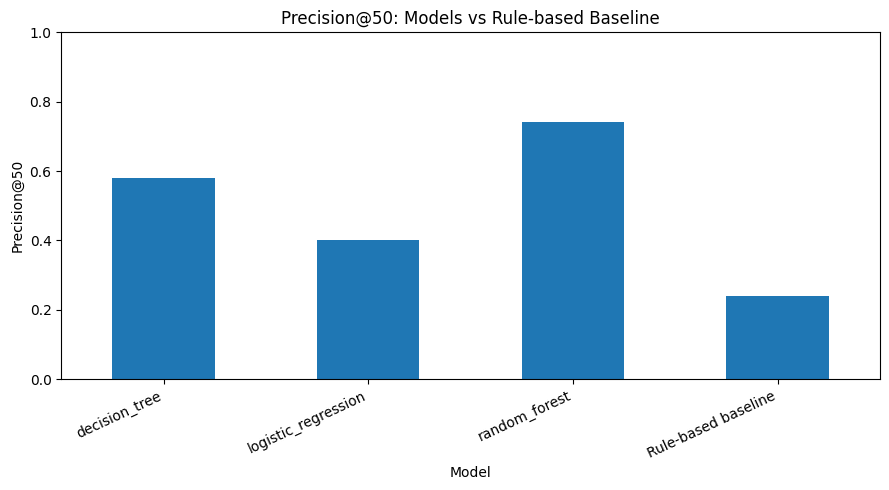

In [18]:

import matplotlib.pyplot as plt

plot_df = comparison_df.set_index("Model")

ax = plot_df[["Precision@50"]].plot(
    kind="bar",
    legend=False,
    figsize=(9, 5)
)

ax.set_title("Precision@50: Models vs Rule-based Baseline")
ax.set_ylabel("Precision@50")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [19]:

print("MODEL COMPARISON RESULTS")

for name, metrics in results["models"].items():
    print("\nModel:", name)
    print("Precision@50:", metrics["precision_at_50"])
    print("ROC-AUC:", metrics["roc_auc"])
    print("Average Precision:", metrics["average_precision"])
    print("F1:", metrics["f1"])
    print("Recall:", metrics["recall"])

print("\nRULE-BASED BASELINE")
for key, value in results["baseline"].items():
    print(key, ":", value)

print("\nBEST MODEL")
print(results["best_model"]["name"])
print("Selection metric:", results["best_model"]["selection_metric"])


MODEL COMPARISON RESULTS

Model: decision_tree
Precision@50: 0.58
ROC-AUC: 0.7415203737887913
Average Precision: 0.5753189989001579
F1: 0.6338851022395326
Recall: 0.7161716171617162

Model: logistic_regression
Precision@50: 0.4
ROC-AUC: 0.7002914980763613
Average Precision: 0.5215418768632023
F1: 0.5662451896646509
Recall: 0.5665566556655666

Model: random_forest
Precision@50: 0.74
ROC-AUC: 0.7500295227262839
Average Precision: 0.6182189675945406
F1: 0.6395458845789972
Recall: 0.7436743674367436

RULE-BASED BASELINE
baseline_accuracy : 0.6086021505376344
baseline_average_precision : 0.46760658636934826
baseline_f1 : 0.2743221690590112
baseline_precision : 0.4985507246376812
baseline_precision_at_100 : 0.36
baseline_precision_at_20 : 0.15
baseline_precision_at_50 : 0.24
baseline_recall : 0.18921892189218922
baseline_roc_auc : 0.6268917852237201

BEST MODEL
random_forest
Selection metric: precision_at_50


## 5. Limitations

*What this work cannot claim.*


### Limitations

This project has several limitations.

1. **Proxy target:** The target is derived from the observed trend direction. It does not represent a confirmed future decline or recovery.
2. **Starter dataset scope:** The analysis uses a 30,000-row anonymized starter dataset, not the full warehouse release.
3. **Aggregated measurements:** The starter data contains aggregated performance windows. It does not provide a complete daily time series for this experiment.
4. **Validation scope:** Client-holdout validation tests performance on clients not used for training, but it does not prove that the model will perform equally well on every future client or time period.
5. **Missing data:** Some content and keyword measurements are unavailable. The preparation pipeline handles missing values, but this may affect model performance.
6. **No causal conclusion:** The analysis does not test whether refreshing a page causes more traffic, clicks, or engagement.
7. **Human judgement required:** The ranked output may contain false positives and false negatives. Every recommendation requires manual review.

Therefore, the model should be treated as a decision-support tool for prioritising content review, not as an automatic content-update system.


In [20]:

print("LIMITATION CHECK")

print("Dataset rows:", results["input_rows"])
print("Training rows:", results["train_rows"])
print("Testing rows:", results["test_rows"])
print("Validation strategy:", results["split_strategy"])
print("Target definition:", results["target"])
print("Target positive rate:", round(results["target_positive_rate"], 4))

print("\nInterpretation:")
print("The model evaluates an observed trend-based proxy label.")
print("It does not establish future decline or causal improvement.")
print("Human review is required before any content action.")


LIMITATION CHECK
Dataset rows: 30000
Training rows: 27675
Testing rows: 2325
Validation strategy: client_holdout
Target definition: is_declining_label
Target positive rate: 0.5421

Interpretation:
The model evaluates an observed trend-based proxy label.
It does not establish future decline or causal improvement.
Human review is required before any content action.


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*


### Ranked recommendations

The ranked queue should be used to help content reviewers decide which items to inspect first.

**Priority 1 — Review high-scoring items with strong visibility.**  
Start with items ranked near the top of the queue, especially where the model score and search visibility indicate a review opportunity. Check whether the observed decline is meaningful and whether the page still matches the user's search intent.

**Priority 2 — Investigate click-through-rate opportunities.**  
For items flagged for CTR review, inspect search snippets, titles, descriptions, and the match between the page and its search intent. Do not change these elements automatically.

**Priority 3 — Review content freshness and depth.**  
For older or shorter content, check whether the information is outdated, incomplete, or missing useful details. Update only when editorial review supports the change.

**Priority 4 — Investigate engagement signals.**  
For items flagged for engagement review, inspect content structure, readability, and whether the page satisfies the visitor's needs.

**Priority 5 — Monitor lower-priority items.**  
Items with weaker evidence can remain in a monitoring group and be reviewed when new performance data becomes available.

All recommendations are suggestions for human investigation. The model does not decide whether a page must be rewritten, removed, or published.


In [21]:

queue_path = repo_path / "outputs/refresh_queue.csv"
queue_df = pd.read_csv(queue_path)

print("Total queue rows:", len(queue_df))

print("\nConfidence groups:")
display(queue_df["confidence"].value_counts().to_frame("Count"))

print("\nSuggested actions:")
display(queue_df["suggested_action"].value_counts().to_frame("Count"))

print("\nTop 10 recommendations (without identifiers):")

safe_columns = [
    "final_rank",
    "final_refresh_score",
    "best_model_probability",
    "confidence",
    "suggested_action",
    "final_reason_codes",
    "impressions_90d",
    "sessions_90d"
]

display(queue_df[safe_columns].head(10))


Total queue rows: 30000

Confidence groups:


,Count
confidence,
low,15000
medium,11398
high,3602



Suggested actions:


,Count
suggested_action,
monitor,13083
refresh,8188
refresh_and_review_ctr,6654
refresh_and_review_engagement,1993
expand_and_refresh,82



Top 10 recommendations (without identifiers):


,final_rank,final_refresh_score,best_model_probability,confidence,suggested_action,final_reason_codes,impressions_90d,sessions_90d
0,1,81.734212,0.783472,high,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|low...,12834,66
1,2,81.603243,0.849842,medium,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,2498,9
2,3,81.544618,0.789490,high,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,8064,23
3,4,81.169731,0.776297,high,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,13790,27
4,5,80.957565,0.816010,medium,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,3393,5
5,6,80.798090,0.796332,high,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,5811,14
6,7,80.650656,0.846499,high,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,1622,20
7,8,80.432641,0.827496,medium,refresh,declining_with_demand|model_decline_risk|visib...,4366,8
8,9,80.428403,0.844030,medium,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,1597,5
9,10,80.428243,0.845325,medium,refresh,declining_with_demand|model_decline_risk|visib...,3867,5


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*


### Research artifacts

The research paper uses the following outputs to communicate the findings:

1. **Model comparison table:** Compares the three machine learning models with the rule-based baseline using the same validation split.
2. **Precision@50 chart:** Shows how well each method ranks items carrying the declining label near the top of the review queue.
3. **Action distribution:** Summarises the suggested actions in the generated queue.
4. **Confidence distribution:** Shows how the queue is divided into high, medium, and low confidence groups.
5. **Feature importance chart:** Shows which input features contributed most to the selected model's ranking.

These artifacts provide a compact view of the experiment, its model performance, and the practical review recommendations.



action_mix.svg


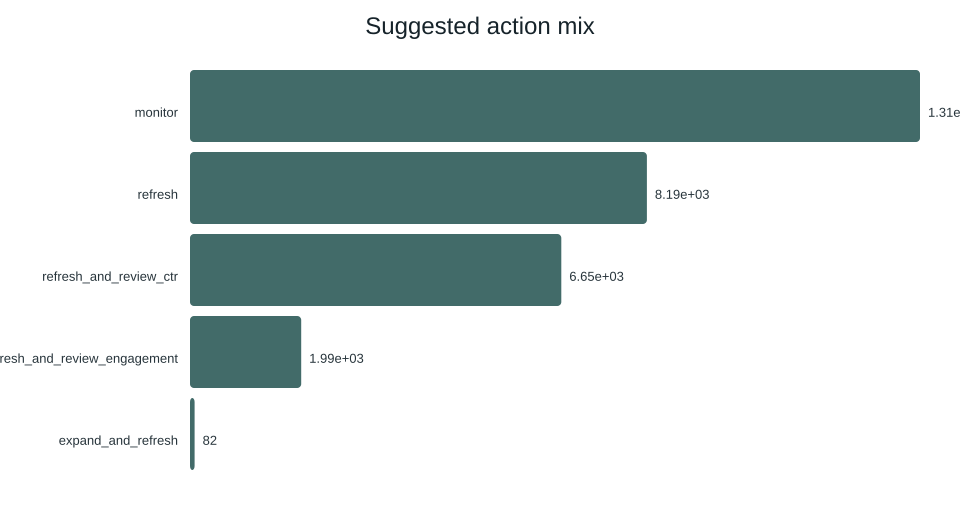


confidence_mix.svg


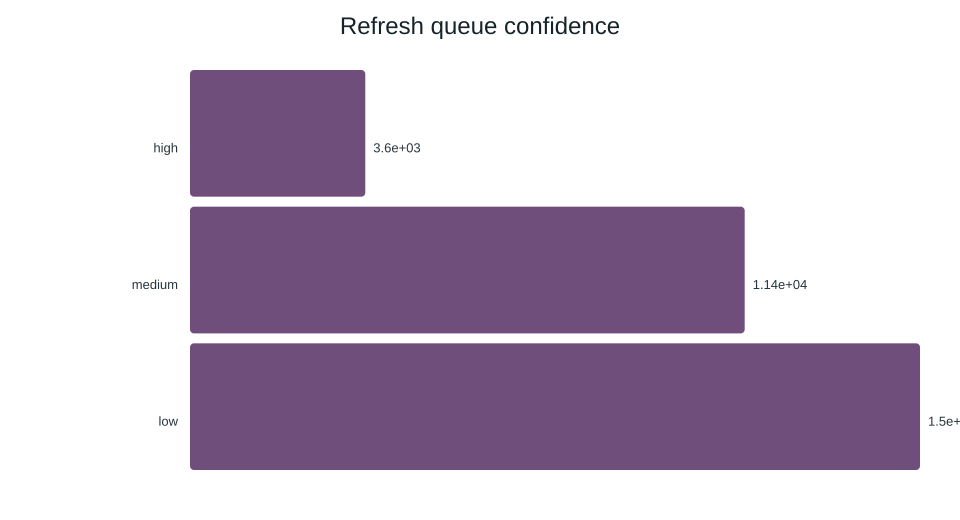


top_reason_codes.svg


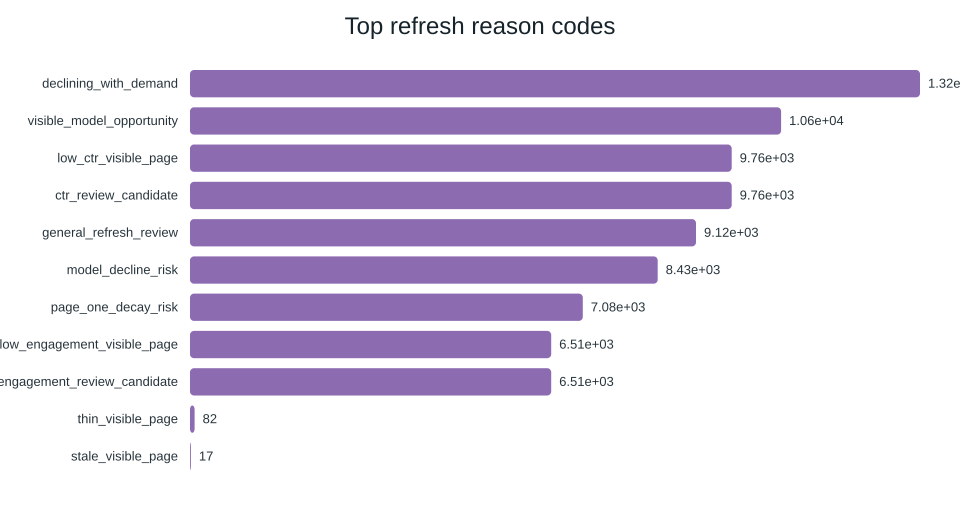


top_feature_importance.svg


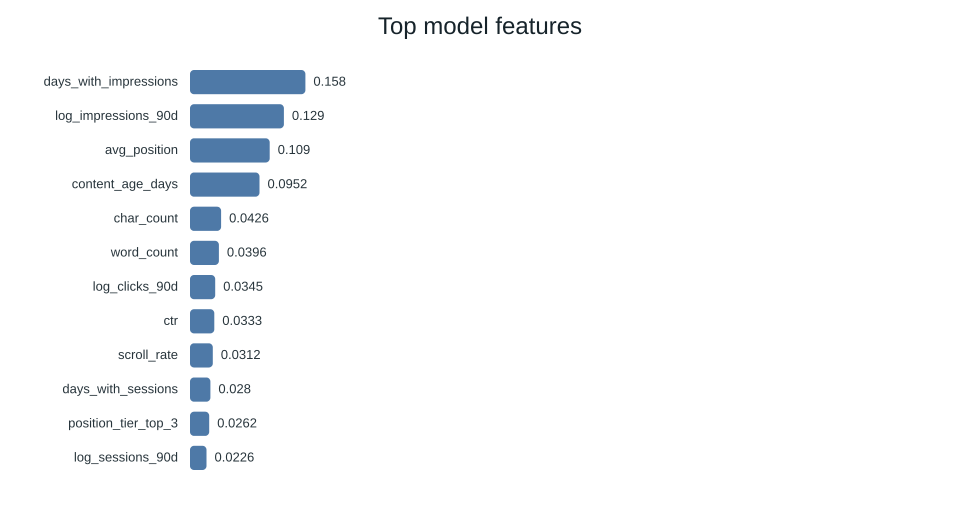


trend_distribution.svg


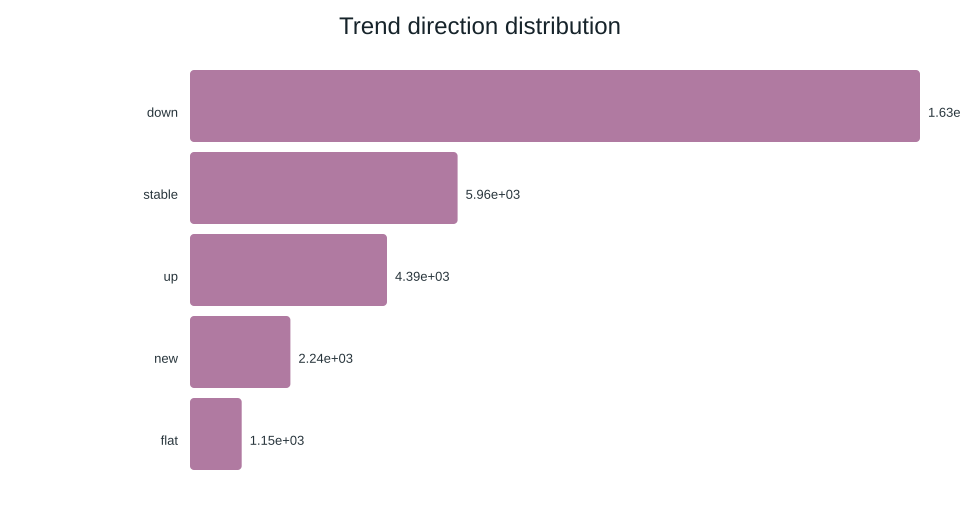


Paper figures folder: /content/keerthi-flyrank-ml-internship-2026/work/figures


In [22]:

from IPython.display import SVG, display
import shutil

chart_dir = repo_path / "outputs/charts"
paper_figures = repo_path / "work/figures"
paper_figures.mkdir(parents=True, exist_ok=True)

chart_names = [
    "action_mix.svg",
    "confidence_mix.svg",
    "top_reason_codes.svg",
    "top_feature_importance.svg",
    "trend_distribution.svg"
]

for chart_name in chart_names:
    source = chart_dir / chart_name

    if source.exists():
        destination = paper_figures / chart_name
        shutil.copy2(source, destination)

        print(f"\n{chart_name}")
        display(SVG(filename=str(destination)))
    else:
        print("Chart not found:", chart_name)

print("\nPaper figures folder:", paper_figures)


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.



### Five-minute project demo

**Minute 1 — Problem**

Explain why content teams need a way to identify pages that may require a refresh.

**Minute 2 — Dataset and preparation**

Introduce the anonymized 30,000-row starter dataset, the preparation steps, and the target label.

**Minute 3 — Model development**

Explain the rule-based baseline and the three models: Logistic Regression, Decision Tree, and Random Forest.

**Minute 4 — Results**

Show the model comparison table and Precision@50 chart. Explain the result using the actual validation metrics.

**Minute 5 — Recommendations and limitations**

Show the ranked review queue, explain how a human reviewer can use it, and discuss the proxy-label and validation limitations.



I recently worked on a Machine Learning project as part of the FlyRank AI Internship.

The project explores how machine learning can help identify website content that may need refreshing.

Using an anonymized content-performance dataset, I worked with data preparation, feature engineering, rule-based baselines, Logistic Regression, Decision Trees, Random Forest, and client-aware model evaluation.

One important takeaway was that model evaluation must be done carefully, with leakage checks and honest comparisons against a baseline.

This project helped me understand how machine learning can support real-world decisions while keeping human review involved.

#MachineLearning #Python #DataScience #AIInternship #LearningByDoing



### Employer-facing project summary

I developed a machine learning decision-support project to rank website content items that may require refresh review. I used an anonymized 30,000-row content-performance dataset and compared Logistic Regression, Decision Tree, and Random Forest models against a rule-based baseline using client-aware validation. The project demonstrates my practical understanding of data preparation, feature engineering, model evaluation, leakage awareness, and translating model outputs into human-reviewed recommendations.


In [23]:

# Final capstone verification

raw_df = pd.read_csv(raw_path)
processed_df = pd.read_csv(processed_path)

with open(model_results_path, "r") as f:
    results = json.load(f)

print("1. DATASET")
print("Raw rows:", len(raw_df))
print("Raw columns:", len(raw_df.columns))
print("Processed rows:", len(processed_df))
print("Unique clients:", raw_df["client_id"].nunique()
      if "client_id" in raw_df.columns else "Column unavailable")

print("\n2. MODEL RESULTS")
print("Validation:", results.get("split_strategy"))
print("Best model:", results.get("best_model"))
print("Models:", list(results.get("models", {}).keys()))
print("Baseline available:", "baseline" in results)

print("\n3. QUEUE")
print("Queue rows:", len(queue_df))
print("Queue columns:", list(queue_df.columns))

print("\n4. CHART FILES")
for name in [
    "action_mix.svg",
    "confidence_mix.svg",
    "top_reason_codes.svg",
    "top_feature_importance.svg",
    "trend_distribution.svg"
]:
    path = paper_figures / name
    print(name, ":", path.exists())

print("\n5. MODEL FEATURE EXCLUSIONS")
for field in ["content_id", "client_id",
              "trend_direction", "trend_pct"]:
    print(field, ":", field not in model_features)

print("\nVerification completed.")


1. DATASET
Raw rows: 30000
Raw columns: 44
Processed rows: 30000
Unique clients: 32

2. MODEL RESULTS
Validation: client_holdout
Best model: {'feature_importance_top': [{'feature': 'days_with_impressions', 'importance': 0.15814381552310994}, {'feature': 'log_impressions_90d', 'importance': 0.12863800983285106}, {'feature': 'avg_position', 'importance': 0.10916404306325882}, {'feature': 'content_age_days', 'importance': 0.0951682857931063}, {'feature': 'char_count', 'importance': 0.042608309447693275}, {'feature': 'word_count', 'importance': 0.03960889270361509}, {'feature': 'log_clicks_90d', 'importance': 0.03446333311152628}, {'feature': 'ctr', 'importance': 0.033294927008649805}, {'feature': 'scroll_rate', 'importance': 0.0312259942941279}, {'feature': 'days_with_sessions', 'importance': 0.027995275312542874}, {'feature': 'position_tier_top_3', 'importance': 0.02623452054989111}, {'feature': 'log_sessions_90d', 'importance': 0.02264992439308099}, {'feature': 'age_tier_365+', 'importa